# 7장. 그래프로 데이터의 이야기를 보여주기

이 노트북은 `book/chapters/ch07_visualization.md` 강의안을 초보자가 그대로 따라 하며 이해할 수 있도록 구성한 실습 자료입니다.

이번 장의 핵심은 그래프를 많이 그리는 것이 아니라, **분석 질문에 맞는 그래프를 고르고, 그래프가 보여주는 것과 보여주지 않는 것을 구분하는 것**입니다.


## 0. 이 노트북 사용 방법

아래 셀을 위에서부터 차례대로 실행하세요.

- 이 노트북은 5장에서 만든 `data/processed/*_clean.csv` 파일을 사용합니다.
- 전처리 파일이 없다면 먼저 `python scripts/preprocess_data.py`를 실행하세요.
- 그래프 파일은 `reports/figures/` 폴더에 저장합니다.
- 그래프 해석에서는 관찰과 원인 가설을 반드시 구분합니다.


## 1. 시각화는 분석 질문에서 시작된다

좋은 시각화는 그래프 종류를 많이 아는 데서 시작하지 않습니다. 먼저 어떤 질문에 답하려는지 정해야 합니다.

| 분석 목적 | 적합한 그래프 | 예시 질문 |
|---|---|---|
| 범주별 크기 비교 | 막대그래프 | 카테고리별 매출은 어떻게 다른가? |
| 시간 흐름 확인 | 선 그래프 | 월별 매출은 어떻게 변하는가? |
| 값의 분포 확인 | 히스토그램 | 상품 가격은 어떤 범위에 몰려 있는가? |
| 두 변수 관계 확인 | 산점도 | 가격과 판매 수량은 관계가 있는가? |
| 상위 항목 비교 | 가로 막대그래프 | 구매 금액 상위 고객은 누구인가? |
| 비율 비교 | 막대그래프 또는 파이 차트 | 주문 상태별 비중은 어떻게 되는가? |


## 2. 이번 장에서 만들 그래프

이번 장에서는 6장 EDA에서 만든 질문을 그래프로 표현합니다.

| 시각화 질문 | 사용할 데이터 | 그래프 |
|---|---|---|
| 카테고리별 매출은 어떻게 다른가? | `category_sales` | 막대그래프 |
| 월별 매출은 어떻게 변하는가? | `monthly_sales` | 선 그래프 |
| 상품 가격은 어떤 구간에 몰려 있는가? | `products` | 히스토그램 |
| 상품 가격과 판매 수량은 관계가 있는가? | `product_sales` | 산점도 |
| 구매 금액 상위 고객은 누구인가? | `customer_sales` | 가로 막대그래프 |
| 주문 상태별 주문 수는 어떻게 다른가? | `orders` | 막대그래프 |


## 3. 패키지와 경로 설정

노트북이 `notebooks/` 폴더 안에서 실행되는 경우와 프로젝트 루트에서 실행되는 경우를 모두 고려해 경로를 설정합니다.


In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt

CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == 'notebooks':
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = PROJECT_ROOT / 'reports'
FIGURE_DIR = REPORT_DIR / 'figures'

REPORT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('현재 실행 위치:', CURRENT_DIR)
print('프로젝트 루트:', PROJECT_ROOT)
print('전처리 데이터 폴더:', PROCESSED_DIR)
print('그래프 저장 폴더:', FIGURE_DIR)


현재 실행 위치: C:\Users\신윤철\Documents\llm-data-analysis-study\chapter07
프로젝트 루트: C:\Users\신윤철\Documents\llm-data-analysis-study\chapter07
전처리 데이터 폴더: C:\Users\신윤철\Documents\llm-data-analysis-study\chapter07\data\processed
그래프 저장 폴더: C:\Users\신윤철\Documents\llm-data-analysis-study\chapter07\reports\figures


## 4. 한글 폰트 설정

matplotlib에서 한글 제목이나 축 이름을 사용하면 글자가 깨질 수 있습니다. Windows 환경에서는 보통 `Malgun Gothic`을 사용합니다. Mac은 `AppleGothic`, Linux는 `NanumGothic`을 사용할 수 있습니다.


In [2]:
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

print('matplotlib 한글 폰트 설정 완료')


matplotlib 한글 폰트 설정 완료


## 5. 전처리 데이터 불러오기

7장은 5장에서 저장한 전처리 데이터를 사용합니다. 파일이 없다면 터미널에서 `python scripts/preprocess_data.py`를 먼저 실행하세요.


In [3]:
required_files = [
    PROCESSED_DIR / 'customers_clean.csv',
    PROCESSED_DIR / 'products_clean.csv',
    PROCESSED_DIR / 'orders_clean.csv',
    PROCESSED_DIR / 'order_items_clean.csv',
]

missing_files = [path for path in required_files if not path.exists()]
if missing_files:
    for path in missing_files:
        print('누락 파일:', path)
    raise FileNotFoundError('전처리 파일이 없습니다. 먼저 python scripts/preprocess_data.py 를 실행하세요.')

customers = pd.read_csv(PROCESSED_DIR / 'customers_clean.csv')
products = pd.read_csv(PROCESSED_DIR / 'products_clean.csv')
orders = pd.read_csv(PROCESSED_DIR / 'orders_clean.csv')
order_items = pd.read_csv(PROCESSED_DIR / 'order_items_clean.csv')

print('전처리 데이터 불러오기 완료')


전처리 데이터 불러오기 완료


In [4]:
orders['order_date'] = pd.to_datetime(orders['order_date'], errors='coerce')

if 'order_month' not in orders.columns:
    orders['order_month'] = orders['order_date'].dt.to_period('M').astype(str)

if 'line_total' not in order_items.columns:
    order_items['line_total'] = order_items['quantity'] * order_items['unit_price']

print('customers:', customers.shape)
print('products:', products.shape)
print('orders:', orders.shape)
print('order_items:', order_items.shape)


customers: (150, 6)
products: (96, 4)
orders: (300, 7)
order_items: (752, 6)


## 6. 시각화를 위한 집계 데이터 만들기

그래프를 그리기 전에 필요한 집계표를 만듭니다. 대부분의 시각화는 원본 데이터를 바로 그리기보다, 질문에 맞게 요약한 표를 만든 뒤 그립니다.


In [5]:
completed_orders = orders.loc[
    orders["order_status"].eq("completed"),
    ["order_id", "customer_id", "order_date"],
].copy()

completed_items = order_items.merge(
    completed_orders,
    on="order_id",
    how="inner",
    validate="many_to_one",
)
sales_items = completed_items.merge(
    products,
    on="product_id",
    how="left",
    validate="many_to_one",
)
sales_items["category"] = sales_items["category"].fillna("Unmapped")
sales_items["line_total"] = sales_items["quantity"] * sales_items["unit_price"]

print("completed orders:", completed_orders.shape)
print("completed order items:", sales_items.shape)
print("unmapped categories:", (sales_items["category"] == "Unmapped").sum())
sales_items.head()

completed orders: (180, 3)
completed order items: (446, 11)
unmapped categories: 16


,order_item_id,order_id,product_id,quantity,unit_price,line_total,customer_id,order_date,product_name,category,price
0,1,1,39,2.0,172000.0,344000.0,144,2026-07-12,뷰티 상품 039,뷰티,172000.0
1,2,2,26,4.0,79000.0,316000.0,149,2025-10-02,뷰티 상품 026,뷰티,79000.0
2,3,2,46,3.0,87000.0,261000.0,149,2025-10-02,생활용품 상품 046,생활용품,87000.0
3,4,2,80,1.0,187000.0,187000.0,149,2025-10-02,패션 상품 080,패션,187000.0
4,5,2,91,5.0,125000.0,625000.0,149,2025-10-02,전자기기 상품 091,전자기기,125000.0


In [6]:
category_sales = (
    sales_items.groupby("category", as_index=False)
    .agg(
        total_quantity=("quantity", "sum"),
        total_sales=("line_total", "sum"),
    )
    .sort_values("total_sales", ascending=False)
)
category_sales["sales_ratio"] = (
    category_sales["total_sales"] / category_sales["total_sales"].sum() * 100
).round(2)
category_sales

,category,total_quantity,total_sales,sales_ratio
10,패션,290.0,32940000.0,23.31
7,식품,226.0,25035000.0,17.71
9,전자기기,176.0,21485000.0,15.20
1,도서,174.0,17663000.0,12.50
3,뷰티,168.0,17103000.0,12.10
6,스포츠,165.0,13237000.0,9.37
5,생활용품,108.0,7001000.0,4.95
0,Unmapped,34.0,4015000.0,2.84
4,생활 용품,17.0,2108000.0,1.49
2,뷰 티,12.0,648000.0,0.46


In [7]:
order_sales = completed_items.copy()
order_sales["order_date"] = pd.to_datetime(order_sales["order_date"], errors="coerce")
order_sales["order_month"] = (
    order_sales["order_date"].dt.to_period("M").astype("string").fillna("Unknown")
)
monthly_sales = (
    order_sales.groupby("order_month", as_index=False)
    .agg(
        total_sales=("line_total", "sum"),
        order_count=("order_id", "nunique"),
    )
    .sort_values("order_month")
)
monthly_sales

,order_month,total_sales,order_count
0,2025-07,9561000.0,11
1,2025-08,9362000.0,17
2,2025-09,5299000.0,4
3,2025-10,12629000.0,17
4,2025-11,9583000.0,16
5,2025-12,8581000.0,12
6,2026-01,8135000.0,9
7,2026-02,7689000.0,12
8,2026-03,7247000.0,13
9,2026-04,11459000.0,14


In [8]:
product_sales = (
    sales_items.groupby(["product_id", "product_name", "category", "price"], as_index=False)
    .agg(
        total_quantity=("quantity", "sum"),
        total_sales=("line_total", "sum"),
    )
    .sort_values("total_sales", ascending=False)
)
product_sales.head()

,product_id,product_name,category,price,total_quantity,total_sales
70,75,스포츠 상품 075,스포츠,183000.0,37.0,6771000.0
90,96,패션 상품 096,패션,96000.0,70.0,6720000.0
91,97,패션 상품 097,패션,187000.0,26.0,4862000.0
61,65,식품 상품 065,식품,193000.0,22.0,4246000.0
50,54,전자기기 상품 054,전자기기,152000.0,26.0,3952000.0


In [9]:
customer_sales_base = order_sales.merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one",
)
group_columns = ["customer_id", "city"]
if "name" in customer_sales_base.columns:
    group_columns = ["customer_id", "name", "city"]
customer_sales = (
    customer_sales_base.groupby(group_columns, as_index=False)
    .agg(
        order_count=("order_id", "nunique"),
        total_sales=("line_total", "sum"),
    )
    .sort_values("total_sales", ascending=False)
)
customer_sales.head()

,customer_id,name,city,order_count,total_sales
1,3,이예우,서울,3,6702000.0
7,14,임서영,대구,4,5204000.0
57,90,윤서미,수원,3,4311000.0
59,93,윤도우,울산,4,4001000.0
47,65,오수민,광주,6,3977000.0


In [10]:
order_status = orders['order_status'].value_counts(dropna=False).reset_index()
order_status.columns = ['order_status', 'order_count']
order_status


,order_status,order_count
0,completed,180
1,cancelled,63
2,refunded,57


## 7. 카테고리별 매출 막대그래프

카테고리별 매출은 범주별 크기 비교이므로 막대그래프가 적합합니다. 그래프는 화면에 표시하고 동시에 PNG 파일로 저장합니다.


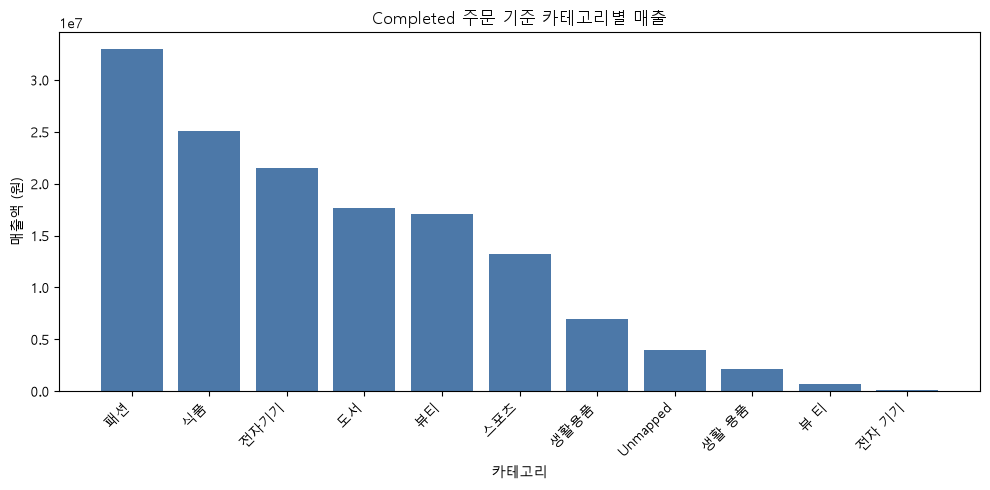

In [11]:
plt.figure(figsize=(10, 5))
plt.bar(category_sales["category"], category_sales["total_sales"], color="#4C78A8")
plt.title("Completed 주문 기준 카테고리별 매출")
plt.xlabel("카테고리")
plt.ylabel("매출액 (원)")
plt.xticks(rotation=45, ha="right")
plt.ylim(bottom=0)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "ch07_category_sales_bar.png", dpi=150, bbox_inches="tight")
plt.show()

해석 예시:

> 관찰: 카테고리별 매출 크기가 서로 다르게 나타납니다.
> 가설: 매출 차이는 판매 수량 또는 평균 단가 차이에서 비롯되었을 수 있습니다.
> 추가 분석: 카테고리별 판매 수량과 평균 단가를 함께 확인해야 합니다.


## 8. 월별 매출 선 그래프

월별 매출은 시간 흐름을 보는 문제이므로 선 그래프가 적합합니다. x축 순서가 월 순서대로 정렬되어 있어야 합니다.


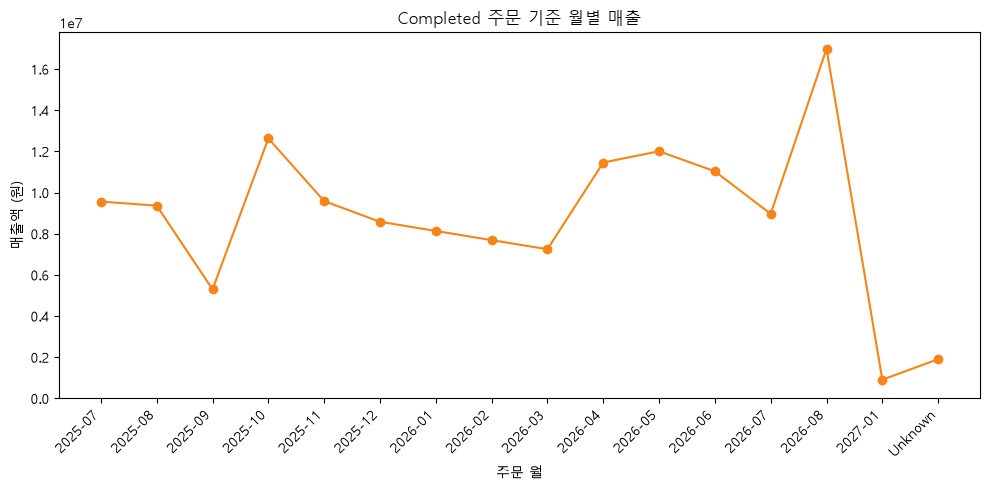

In [12]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_sales["order_month"], monthly_sales["total_sales"], marker="o", color="#F58518")
plt.title("Completed 주문 기준 월별 매출")
plt.xlabel("주문 월")
plt.ylabel("매출액 (원)")
plt.xticks(rotation=45, ha="right")
plt.ylim(bottom=0)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "ch07_monthly_sales_line.png", dpi=150, bbox_inches="tight")
plt.show()

월별 매출이 증가하거나 감소해도 그 원인을 바로 단정하면 안 됩니다. 주문 수, 평균 주문 금액, 프로모션 여부, 특정 카테고리 매출 변화를 추가로 확인해야 합니다.


## 9. 상품 가격 분포 히스토그램

히스토그램은 숫자형 데이터가 어느 구간에 많이 몰려 있는지 보여줍니다. 상품 가격 분포를 보면 저가/중가/고가 상품이 어떻게 분포하는지 확인할 수 있습니다.


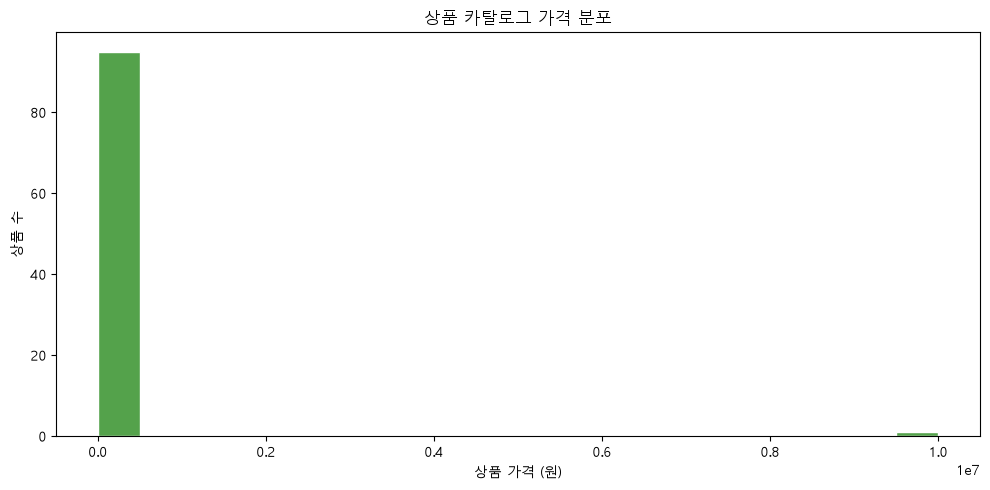

In [13]:
plt.figure(figsize=(10, 5))
plt.hist(products["price"], bins=20, color="#54A24B", edgecolor="white")
plt.title("상품 카탈로그 가격 분포")
plt.xlabel("상품 가격 (원)")
plt.ylabel("상품 수")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "ch07_product_price_hist.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. 상품 가격과 판매 수량 산점도

산점도는 두 숫자형 변수의 관계를 탐색할 때 사용합니다. 여기서는 상품 가격과 총 판매 수량 사이의 관계를 확인합니다. 산점도만으로 원인 관계를 단정해서는 안 됩니다.


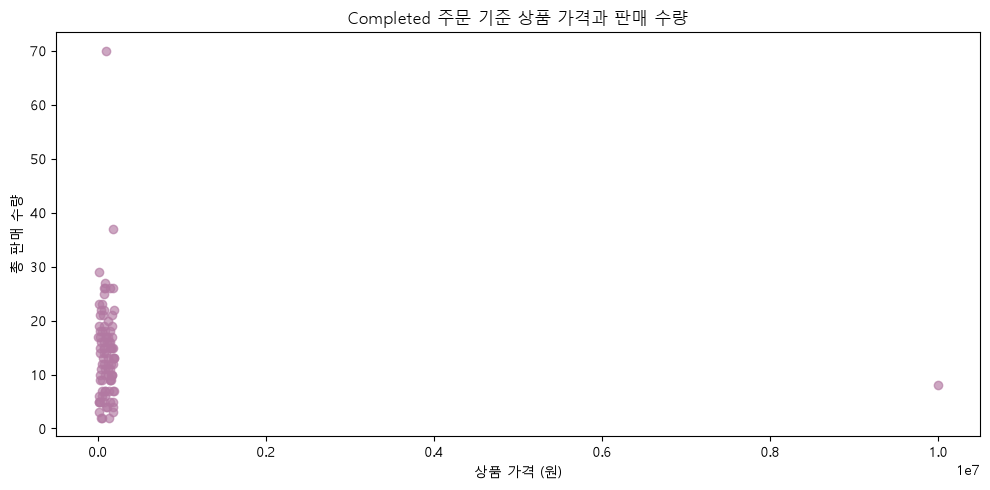

In [14]:
plt.figure(figsize=(10, 5))
plt.scatter(product_sales["price"], product_sales["total_quantity"], alpha=0.65, color="#B279A2")
plt.title("Completed 주문 기준 상품 가격과 판매 수량")
plt.xlabel("상품 가격 (원)")
plt.ylabel("총 판매 수량")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "ch07_price_quantity_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. 구매 금액 상위 고객 가로 막대그래프

상위 항목을 비교할 때는 가로 막대그래프가 읽기 좋습니다. 고객명은 개인정보가 될 수 있으므로 보고서에서는 익명화 라벨을 사용하는 것이 좋습니다.


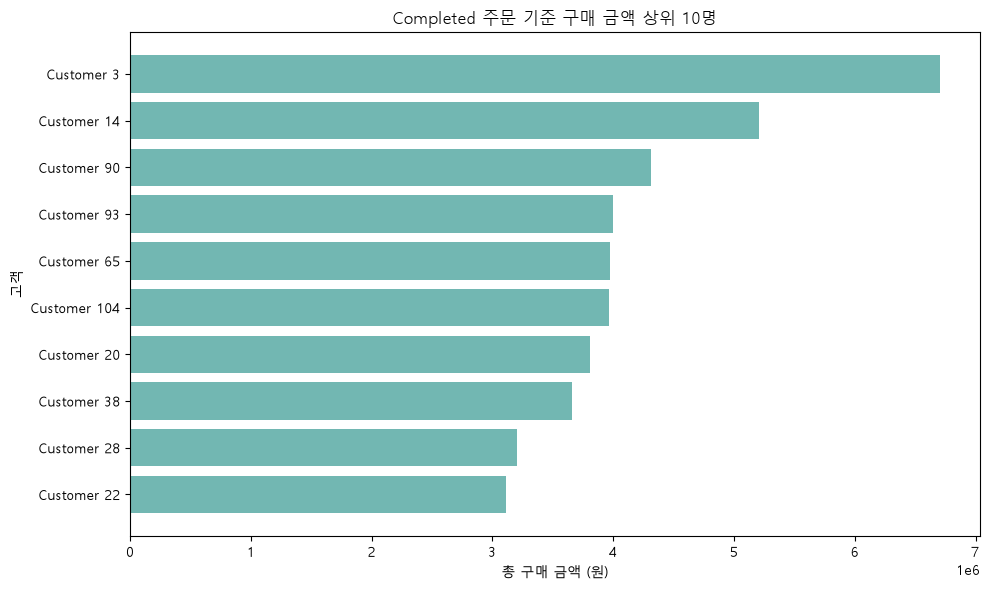

In [15]:
top_customers = customer_sales.head(10).copy()
top_customers["customer_label"] = "Customer " + top_customers["customer_id"].astype(str)
top_customers = top_customers.sort_values("total_sales")

plt.figure(figsize=(10, 6))
plt.barh(top_customers["customer_label"], top_customers["total_sales"], color="#72B7B2")
plt.title("Completed 주문 기준 구매 금액 상위 10명")
plt.xlabel("총 구매 금액 (원)")
plt.ylabel("고객")
plt.xlim(left=0)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "ch07_top_customers_barh.png", dpi=150, bbox_inches="tight")
plt.show()

고객별 구매 금액 상위 그래프는 우수 고객 후보를 확인하는 데 유용합니다. 하지만 한 번에 많이 구매한 고객과 여러 번 반복 구매한 고객은 구분해서 해석해야 합니다.


## 12. 주문 상태별 주문 수 막대그래프

주문 상태별 주문 수는 완료, 취소, 환불 등 주문 상태의 분포를 확인하는 데 사용합니다.


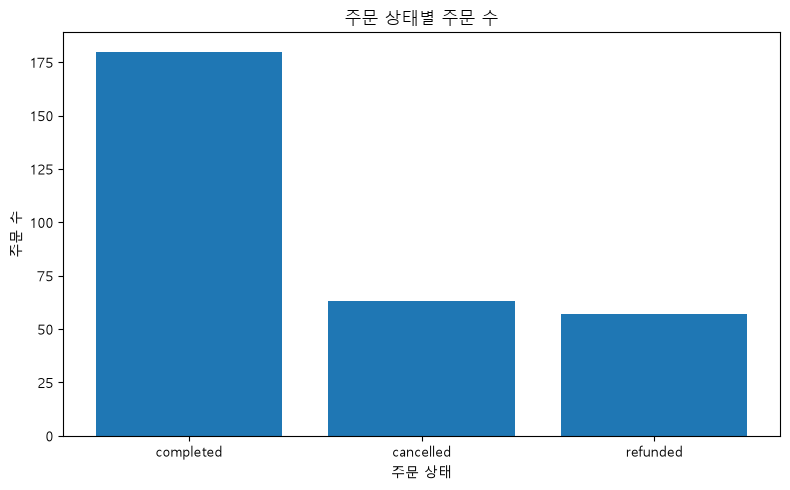

In [16]:
plt.figure(figsize=(8, 5))
plt.bar(order_status['order_status'], order_status['order_count'])
plt.title('주문 상태별 주문 수')
plt.xlabel('주문 상태')
plt.ylabel('주문 수')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_order_status_bar.png', dpi=150, bbox_inches='tight')
plt.show()


## 13. 저장된 그래프 확인하기

생성된 그래프 파일을 확인합니다. 보고서나 발표 자료에 사용할 수 있도록 `reports/figures` 폴더에 저장했습니다.


In [17]:
list(FIGURE_DIR.glob('ch07_*.png'))


[WindowsPath('C:/Users/신윤철/Documents/llm-data-analysis-study/chapter07/reports/figures/ch07_category_sales_bar.png'),
 WindowsPath('C:/Users/신윤철/Documents/llm-data-analysis-study/chapter07/reports/figures/ch07_monthly_sales_line.png'),
 WindowsPath('C:/Users/신윤철/Documents/llm-data-analysis-study/chapter07/reports/figures/ch07_order_status_bar.png'),
 WindowsPath('C:/Users/신윤철/Documents/llm-data-analysis-study/chapter07/reports/figures/ch07_price_quantity_scatter.png'),
 WindowsPath('C:/Users/신윤철/Documents/llm-data-analysis-study/chapter07/reports/figures/ch07_product_price_hist.png'),
 WindowsPath('C:/Users/신윤철/Documents/llm-data-analysis-study/chapter07/reports/figures/ch07_top_customers_barh.png')]

## 14. 시각화 요약표 만들기

각 그래프의 목적과 해석 포인트를 표로 정리하면 이후 보고서 작성이 쉬워집니다.


In [18]:
visualization_summary = pd.DataFrame({
    "chart": ["카테고리별 매출", "월별 매출", "상품 가격 분포", "가격-판매수량"],
    "scope": ["completed 주문", "completed 주문", "전체 상품 카탈로그", "completed 주문"],
    "source_table": ["category_sales", "monthly_sales", "products", "product_sales"],
})
visualization_summary

,chart,scope,source_table
0,카테고리별 매출,completed 주문,category_sales
1,월별 매출,completed 주문,monthly_sales
2,상품 가격 분포,전체 상품 카탈로그,products
3,가격-판매수량,completed 주문,product_sales


## 15. 시각화 요약 보고서 저장하기

시각화 목적, 생성한 그래프 목록, 해석 포인트, 주의사항을 Markdown 보고서로 저장합니다.


In [19]:
summary_text = f"""# Chapter 07 시각화 요약

## 분석 범위
금액 관련 그래프는 `order_status == completed` 주문만 사용했다.

## 그래프 목록
```text
{visualization_summary.to_string(index=False)}
```

## 교차 검증
- completed 주문 항목 매출 합계: {sales_items['line_total'].sum():,.0f}원
- 카테고리별 매출 합계: {category_sales['total_sales'].sum():,.0f}원
- 월별 매출 합계: {monthly_sales['total_sales'].sum():,.0f}원
"""
print(summary_text)
(REPORT_DIR / "ch07_visualization_summary.md").write_text(summary_text, encoding="utf-8")

# Chapter 07 시각화 요약

## 분석 범위
금액 관련 그래프는 `order_status == completed` 주문만 사용했다.

## 그래프 목록
```text
   chart        scope   source_table
카테고리별 매출 completed 주문 category_sales
   월별 매출 completed 주문  monthly_sales
상품 가격 분포   전체 상품 카탈로그       products
 가격-판매수량 completed 주문  product_sales
```

## 교차 검증
- completed 주문 항목 매출 합계: 141,340,000원
- 카테고리별 매출 합계: 141,340,000원
- 월별 매출 합계: 141,340,000원



388

## 16. 소스 모듈로 같은 시각화 실행하기

위에서 노트북으로 한 단계씩 실행한 시각화는 `src/visualization.py`에 함수로 정리되어 있습니다. 반복 실행하거나 프로젝트 코드로 관리하려면 소스 모듈을 사용하는 것이 좋습니다.


In [20]:
# 노트북에서 사용한 집계표와 생성 파일을 다시 확인한다.
visualization_summary
list(FIGURE_DIR.glob("ch07_*.png"))

[WindowsPath('C:/Users/신윤철/Documents/llm-data-analysis-study/chapter07/reports/figures/ch07_category_sales_bar.png'),
 WindowsPath('C:/Users/신윤철/Documents/llm-data-analysis-study/chapter07/reports/figures/ch07_monthly_sales_line.png'),
 WindowsPath('C:/Users/신윤철/Documents/llm-data-analysis-study/chapter07/reports/figures/ch07_order_status_bar.png'),
 WindowsPath('C:/Users/신윤철/Documents/llm-data-analysis-study/chapter07/reports/figures/ch07_price_quantity_scatter.png'),
 WindowsPath('C:/Users/신윤철/Documents/llm-data-analysis-study/chapter07/reports/figures/ch07_product_price_hist.png'),
 WindowsPath('C:/Users/신윤철/Documents/llm-data-analysis-study/chapter07/reports/figures/ch07_top_customers_barh.png')]

## 17. 스크립트로 한 번에 실행하기

노트북에서 한 단계씩 이해한 시각화 과정을 스크립트로도 실행할 수 있습니다. 터미널에서 프로젝트 루트 기준으로 아래 명령을 실행합니다.

```bash
python scripts/run_visualization.py
```

이 스크립트는 7장 그래프 파일 6개와 `reports/ch07_visualization_summary.md`를 자동으로 저장합니다.


## 18. LLM에게 그래프 선택과 해석 요청하기

LLM은 그래프 선택, matplotlib 코드 작성, 해석 문장 작성에 도움을 줄 수 있습니다. 하지만 그래프 해석은 반드시 실제 데이터와 비교해야 합니다.

```text
온라인 쇼핑몰 데이터에서 다음 분석 질문을 시각화하려고 합니다.

분석 질문:
1. 카테고리별 매출은 어떻게 다른가?
2. 월별 매출은 어떻게 변하는가?
3. 상품 가격은 어떤 구간에 몰려 있는가?
4. 상품 가격과 판매 수량은 관계가 있는가?
5. 구매 금액 상위 고객은 누구인가?

각 질문에 적합한 그래프 종류를 추천해 주세요.
각 그래프를 선택한 이유와 주의할 점도 함께 설명해 주세요.
```


## 19. 그래프 해석 요청 예시

그래프 해석을 요청할 때는 데이터에 없는 원인을 단정하지 말라는 조건을 넣는 것이 좋습니다.

```text
다음은 카테고리별 매출 그래프를 만들기 위한 요약 데이터입니다.

category,total_sales,sales_ratio
전자기기,12500000,42.5
생활용품,7800000,26.5
패션,6200000,21.1
식품,2900000,9.9

이 그래프를 보고서에 넣을 수 있도록 해석 문장을 작성해 주세요.

조건:
- 데이터에 없는 원인을 단정하지 말 것
- 관찰 결과와 원인 가설을 구분할 것
- 추가로 확인해야 할 분석 질문을 제안할 것
- 초보자도 이해할 수 있게 작성할 것
```


## 20. 시각화 점검 체크리스트

그래프를 보고서에 넣기 전에 아래 항목을 점검합니다.

| 점검 항목 | 확인 |
|---|---|
| 분석 질문에 맞는 그래프를 선택했는가? | □ |
| 그래프 제목이 명확한가? | □ |
| x축과 y축 이름을 표시했는가? | □ |
| 필요한 경우 단위를 표시했는가? | □ |
| 범주형 데이터가 읽기 좋은 순서로 정렬되었는가? | □ |
| 시간 데이터가 올바른 순서로 정렬되었는가? | □ |
| 한글 폰트가 깨지지 않는가? | □ |
| 그래프 해석에서 관찰과 원인을 구분했는가? | □ |
| 개인정보가 필요한 경우 익명화했는가? | □ |
| 그래프 파일을 저장했는가? | □ |


## 21. 실습 과제

아래 과제를 직접 해결해 보세요.

1. 카테고리별 판매 수량 막대그래프를 추가로 그려 보세요.
2. 결제수단별 주문 수 막대그래프를 그려 보세요.
3. 고객 나이 분포 히스토그램을 그려 보세요.
4. 월별 주문 수 선 그래프를 그려 보세요.
5. 고객별 주문 횟수와 총 구매 금액의 관계를 산점도로 그려 보세요.
6. 위 그래프 중 2개를 `reports/figures` 폴더에 저장하세요.


In [21]:
# 과제 1. 카테고리별 판매 수량 막대그래프를 추가로 그려 보세요.


In [22]:
# 과제 2. 결제수단별 주문 수 막대그래프를 그려 보세요.


In [23]:
# 과제 3. 고객 나이 분포 히스토그램을 그려 보세요.


## 22. 정리

이번 장에서는 다음 내용을 실습했습니다.

- 분석 질문에 맞는 그래프 선택
- matplotlib 기본 구조와 한글 폰트 설정
- 시각화를 위한 집계 데이터 준비
- 카테고리별 매출 막대그래프
- 월별 매출 선 그래프
- 상품 가격 분포 히스토그램
- 상품 가격과 판매 수량 산점도
- 구매 금액 상위 고객 가로 막대그래프와 익명화
- 주문 상태별 주문 수 막대그래프
- 그래프 파일 저장과 시각화 요약 보고서 작성
- `src/visualization.py`와 `scripts/run_visualization.py`로 반복 실행 가능한 구조 만들기

다음 장에서는 지금까지 배운 데이터 불러오기, 전처리, EDA, 시각화를 종합하여 중간 실습 프로젝트를 수행합니다.


# 제출 답안

## 제출 정보
- 이름: 신윤철
- GitHub ID: ycshin2002
- 작성일: 2026-10-20
- 최종 Notebook URL: `https://github.com/ycshin2002/llm-data-analysis-study/blob/main/chapter07/chapter07.ipynb`

## 1. 시각화 질문과 그래프 선택
| 질문 | 선택한 그래프 | 선택 이유 |
| --- | --- | --- |
| Completed 주문에서 어떤 카테고리가 매출을 가장 많이 만드는가? | 막대그래프 | 범주별 매출 크기를 같은 기준선에서 비교하기 좋다. |
| Completed 주문 매출은 월별로 어떻게 달라지는가? | 선그래프 | 시간 순서에 따른 변화와 일시적 고점을 확인하기 좋다. |
| 상품 가격은 어떤 분포를 가지는가? | 히스토그램 | 가격이 어느 구간에 몰려 있고 극단값 후보가 있는지 확인하기 좋다. |

## 2. 대표 그래프 1: 카테고리별 매출
![대표 그래프 1](images/graph01.png)

### 원본 집계값
`category_sales`를 사용했으며, completed 주문 항목 446건의 매출 합계는 141,340,000원이다. 식품 카테고리가 32,940,000원으로 가장 높다.

### 결과 관찰
카테고리별 매출 차이가 있으며, 식품·생활용품·전자기기가 상위권이다.

### 나의 해석과 판단
상위 카테고리의 매출 우위는 확인되지만, 판매 수량·상품 가격·상품 수가 함께 작용할 수 있으므로 이것만으로 수요가 높다고 단정하지 않는다.

### 업무·분석적 의미
상위 카테고리는 상품별 매출과 판매 수량을 추가로 확인할 우선 후보이다.

### 한계와 추가 확인 사항
카테고리 표기 정제 과정에서 `Unmapped`가 남아 있으며, 이를 원래 카테고리에 재분류할 수 있는지 확인해야 한다.

## 3. 대표 그래프 2: 월별 매출
![대표 그래프 2](images/graph02.png)

### 원본 집계값
`monthly_sales`를 사용했으며, 월별 합계와 카테고리별 합계는 모두 141,340,000원으로 원본 completed 매출 합계와 일치한다.

### 결과 관찰
2026-08의 월별 매출이 16,980,000원으로 가장 높으며, 2025-09는 5,299,000원으로 낮다.

### 나의 해석과 판단
월별 차이는 사실이지만, 기간 중 주문 수·상품 구성·프로모션 정보가 없으므로 계절성이나 특정 이벤트의 효과라고 결론 내릴 수 없다.

### 업무·분석적 의미
고점과 저점 월의 주문 수 및 카테고리 구성을 비교하면 변동의 후보 원인을 좁힐 수 있다.

### 한계와 추가 확인 사항
날짜 오류 2건은 `Unknown`으로 분리했다. 또한 2027-01은 관측 기간이 짧을 수 있어 다른 월과 단순 비교하면 안 된다.

## 4. 대표 그래프 3: 상품 가격 분포
![대표 그래프 3](images/graph03.png)

### 원본 집계값
`products` 96개 상품의 가격을 사용했다. 중앙값은 94,500원, 최댓값은 9,999,999원이다.

### 결과 관찰
대부분 상품 가격은 낮은 구간에 있고, 고가 쪽으로 긴 꼬리와 극단값 후보가 보인다.

### 나의 해석과 판단
고가 상품은 실제 프리미엄 상품일 수도, 입력 오류일 수도 있으므로 분포만으로 제거하면 안 된다.

### 업무·분석적 의미
상위 가격 상품의 상품명·카테고리·주문 여부를 확인해 가격 정책 또는 데이터 품질 이슈를 구분할 수 있다.

### 한계와 추가 확인 사항
이 그래프는 판매된 상품만이 아니라 전체 상품 카탈로그의 가격 분포다. 매출 분석 범위와 다름을 명시했다.

## 5. 그래프 정확성 점검
- [x] 그래프 값과 집계표 값 일치
- [x] 축 이름 확인
- [x] 단위 확인
- [x] 범례 확인 불필요(단일 계열)
- [x] 날짜 정렬 확인
- [x] 과장될 수 있는 축 범위 확인
- [x] 제목이 분석 범위를 정확히 표현

### 내가 발견한 시각화 위험 또는 개선점
금액 그래프는 0에서 시작하는 축을 사용해 차이를 과장하지 않았다. 월별 그래프의 `Unknown`과 관측 기간이 짧을 수 있는 2027-01은 원인 해석에서 제외 또는 별도 표기해야 한다.

## 6. Chapter 07 최종 판단
### 가장 중요한 그래프 1개와 이유
카테고리별 매출 막대그래프가 가장 중요하다. completed 매출이 어디에 집중되는지 빠르게 보여 주고, 후속 상품·수량 분석의 출발점이 된다.

### 그래프가 보여 준 사실
완료 주문 기준 매출은 카테고리와 월에 따라 다르며, 상품 가격 분포에는 고가 극단값 후보가 있다.

### 그래프만으로 말할 수 없는 것
그래프만으로 매출 차이의 원인, 인과관계, 미래 매출을 말할 수 없다.

### 다음 분석에서 확인할 질문
상위 카테고리 매출은 판매 수량 증가, 고가 상품 판매, 또는 상품 수 차이 중 무엇에 더 크게 좌우되는가?